In [152]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

import warnings
warnings.filterwarnings('ignore')

titanic = pd.read_csv(r"C:\Users\SuNi\Downloads\Titanic-Dataset.csv")
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [153]:
print(titanic.shape)
titanic.info()

(891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [154]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [155]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [156]:
titanic.duplicated().sum()

np.int64(0)

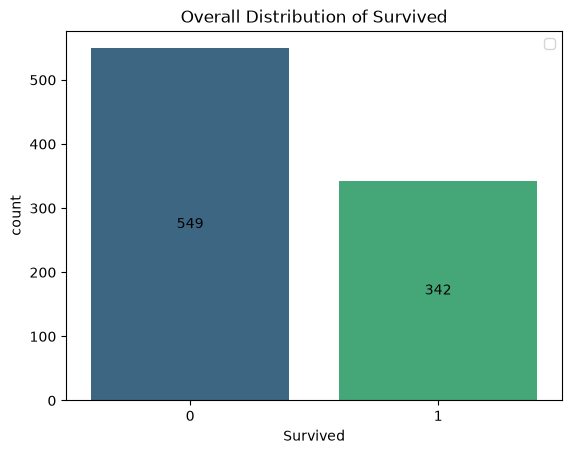

In [157]:
plt.Figure(figsize=(6,4))
ax = sns.countplot(x=titanic['Survived'], palette='viridis')
for container in ax.containers:
    ax.bar_label(container, label_type='center')
plt.title('Overall Distribution of Survived')
plt.legend()
plt.show()

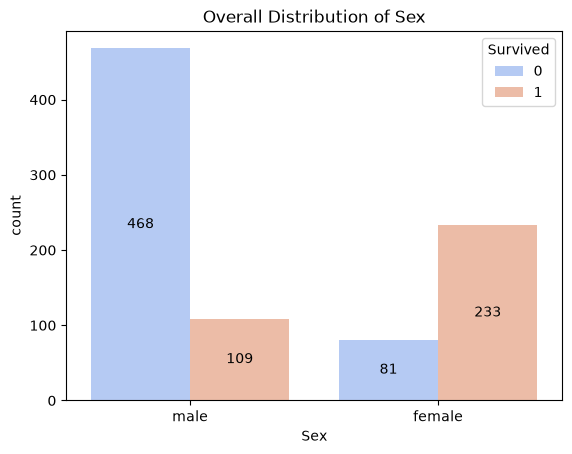

In [158]:
plt.Figure(figsize=(6,4))
ax = sns.countplot(x=titanic['Sex'], hue=titanic['Survived'], palette='coolwarm')
for container in ax.containers:
    ax.bar_label(container, label_type='center')
plt.title('Overall Distribution of Sex')
plt.show()

In [159]:
titanic = titanic.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
titanic.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [160]:
word_cols = ['Embarked']
for col in word_cols:
    titanic[col] = titanic[col].fillna(titanic[col].mode()[0])

num_cols = ['Age', 'Pclass', 'SibSp', 'Parch', 'Fare']
for col in num_cols:
    titanic[col] = titanic[col].fillna(titanic[col].mean())

word_cols = ['Sex', 'Embarked', 'Pclass']
titanic= pd.get_dummies(titanic, columns=word_cols, drop_first=True, dtype=int)

titanic.head()

,Survived,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Pclass_2,Pclass_3
0,0,22.0,1,0,7.2500,1,0,1,0,1
1,1,38.0,1,0,71.2833,0,0,0,0,0
2,1,26.0,0,0,7.9250,0,0,1,0,1
3,1,35.0,1,0,53.1000,0,0,1,0,0
4,0,35.0,0,0,8.0500,1,0,1,0,1


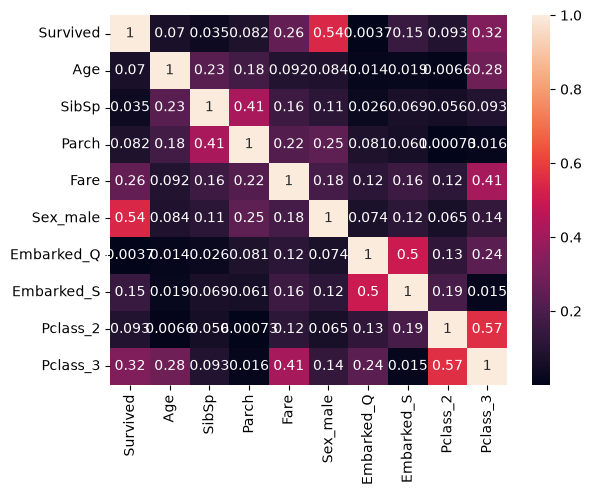

In [161]:
plt.Figure(figsize=(16,15))
corr = abs(titanic.corr(numeric_only=True))
sns.heatmap(corr, annot=True)
plt.show()

In [162]:
X = titanic.drop(['Survived'], axis=1)
y = titanic['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [163]:
models = {
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'K-Neighbors': KNeighborsClassifier(n_neighbors=7),
    'SVM': LinearSVC(random_state=42)    
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy")
    rows.append({"model": name,
                 "CV Accuracy": scores.mean(),
                 "CV Std": scores.std()}),
cv = pd.DataFrame(rows).set_index("model").round(4)
print(cv)

               CV Accuracy  CV Std
model                             
Random Forest       0.8019  0.0295
K-Neighbors         0.7907  0.0386
SVM                 0.8005  0.0291


In [164]:
rows = []                                           
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "F1 Score": f1_score(y_test, pred)})
print(pd.DataFrame(rows).set_index("model").round(4))

               Accuracy  F1 Score
model                            
Random Forest    0.8045    0.7552
K-Neighbors      0.8212    0.7808
SVM              0.7877    0.7324


In [165]:
best = cv['CV Accuracy'].idxmax()
print('\nBest by CV:', best)
print(classification_report(y_test, models[best].predict(X_test), target_names=['Died', 'Survived']))


Best by CV: Random Forest
              precision    recall  f1-score   support

        Died       0.82      0.86      0.84       105
    Survived       0.78      0.73      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.80      0.80      0.80       179

